In [21]:
from scipy.interpolate import interp1d
from scipy.integrate import solve_ivp
from scipy.optimize import root
import matplotlib.pyplot as plt
import math
import numpy as np
# Fundamental constants in SI
G = 6.67430e-11            # gravitational constant [m^3 kg^-1 s^-2]
c = 2.99792458e8           # speed of light [m s^-1]
hbar = 1.054571817e-34     # reduced Planck constant [J s]
M_sun = 1.98847e30         # solar mass [kg]


# Basic unit conversions
eV_to_J = 1.602176634e-19
MeV_to_J = 1.0e6 * eV_to_J

J_to_eV = 1.0 / eV_to_J
J_to_MeV = 1.0 / MeV_to_J

fm_to_m = 1.0e-15
m_to_fm = 1.0 / fm_to_m

km_to_m = 1.0e3
m_to_km = 1.0 / km_to_m

def kg_to_MeV_c2(m_kg):
    return m_kg * c**2 * J_to_MeV


def MeV_c2_to_kg(m_MeV):
    return m_MeV * MeV_to_J / c**2

MeV_fm3_to_J_m3 = MeV_to_J / fm_to_m**3
J_m3_to_MeV_fm3 = 1.0 / MeV_fm3_to_J_m3

def MeV_fm3_to_SI(x):
    return x * MeV_fm3_to_J_m3
def SI_to_MeV_fm3(x):
    return x * J_m3_to_MeV_fm3




In [22]:
# Boundary values from the 2014 paper
#mu in MeV, n0 in fm, P in Mev/fm^3,
n0 = 0.16
n_begin = 1.1 * n0
mu_begin = 977.5
P_begin = 3.542
Gamma_regions = np.array([4.021,1.195])
mu_transition = 1350.0   
mu_end = 2600.0      


gamma1 = Gamma_regions[0]
gamma2 = Gamma_regions[1]

kappa1 = (P_begin/ n_begin**gamma1)
#Transition density by inverting equ 1 
n_transition = (n_begin**(gamma1 - 1.0) + ((gamma1 - 1.0)/ (kappa1 * gamma1))* (mu_transition - mu_begin))**(1.0 / (gamma1 - 1.0))
# Pressure at transition as a result
P_transition = (kappa1 * n_transition**gamma1)
kappa2 = (P_transition/ n_transition**gamma2)

kappa_regions = np.array([kappa1,kappa2])
n_breaks = np.array([n_transition])
P_breaks = np.array([P_transition])
n_start_regions = np.array([n_begin,n_transition])
mu_start_regions = np.array([mu_begin,mu_transition])
print("kappa1 =", kappa1)
print("Transition density =",n_transition,"fm^-3")
print("Transition density / n0 =", n_transition / n0)
print("Transition pressure =",P_transition,"MeV/fm^3")
print("kappa2 =",kappa2)

def poly_density_region(n):
    return np.searchsorted(n_breaks,n,side="right")
def poly_pressure_region(P_MeV):
    return np.searchsorted(P_breaks,P_MeV,side="right")

kappa1 = 3828.618729545717
Transition density = 0.43044306598334575 fm^-3
Transition density / n0 = 2.6902691623959107
Transition pressure = 129.12704549427107 MeV/fm^3
kappa2 = 353.58019697289467


In [23]:
# EOS for : Pressure as a function of baryon dfensity
def poly_pressure_n(n):

    n = np.asarray(n)
    region = poly_density_region(n)
    kappa = kappa_regions[region]
    gamma = Gamma_regions[region]
    #equ 6
    P = (kappa* n**gamma)
    return P

# Rearranging equation 7 for the Baryon Chemical Potential

def poly_mu_n(n):

    n = np.asarray(n)
    region = poly_density_region(n)
    gamma = Gamma_regions[region]
    kappa = kappa_regions[region]
    n_start = n_start_regions[region]
    mu_start = mu_start_regions[region]
    mu = (mu_start+ (gamma* kappa/ (gamma - 1.0)) * ( n**(gamma - 1.0) - n_start**(gamma - 1.0)))
    return mu

# using E = TS - PV + muN, set T = 0 in our case (0 TEMPERATURE)

def poly_energy_n(n):
    P = poly_pressure_n(n)
    mu = poly_mu_n(n)
    E = (mu * n- P)
    return E


def poly_cs2_n(n):

    n = np.asarray(n)

    region = poly_density_region(n)

    gamma = Gamma_regions[region]
    P = poly_pressure_n(n)

    mu = poly_mu_n(n)
    cs2 = (gamma* P/ (mu* n))


    return cs2




In [24]:

def poly_n_from_P_MeV(P_MeV):

    P_MeV = np.asarray(P_MeV)

    region = poly_pressure_region(P_MeV)
    kappa = kappa_regions[region]

    gamma = Gamma_regions[region]
    n = (P_MeV/ kappa)**(1.0 / gamma)

    return n


def poly_e_density(P):
    P_MeV = SI_to_MeV_fm3(P)
    n = poly_n_from_P_MeV(P_MeV)
    E_MeV = poly_energy_n(n)
    E_SI = MeV_fm3_to_SI(E_MeV)
    return E_SI

In [25]:
# ============================================================
# CHECK AGAINST REPRESENTATIVE EOS II
# ============================================================

n_test = (np.array([1.1,1.5,2.1,2.5,2.7,3.5,4.5])* n0)


P_test = poly_pressure_n(n_test)
E_test = poly_energy_n(n_test)
mu_test = poly_mu_n(n_test)

cs2_test = poly_cs2_n(n_test)
for i in range(len(n_test)):

    print(
        f"n/n0 = {n_test[i]/n0:.1f}, "
        f"P = {P_test[i]:.3f}, "
        f"E = {E_test[i]:.3f}, "
        f"mu_B = {mu_test[i]/1000:.4f} GeV, "
        f"cs2 = {cs2_test[i]:.3f}"
    )

n/n0 = 1.1, P = 3.542, E = 168.498, mu_B = 0.9775 GeV, cs2 = 0.083
n/n0 = 1.5, P = 12.327, E = 232.252, mu_B = 1.0191 GeV, cs2 = 0.203
n/n0 = 2.1, P = 47.693, E = 335.227, mu_B = 1.1396 GeV, cs2 = 0.501
n/n0 = 2.5, P = 96.145, E = 412.111, mu_B = 1.2706 GeV, cs2 = 0.761
n/n0 = 2.7, P = 129.685, E = 454.074, mu_B = 1.3513 GeV, cs2 = 0.265
n/n0 = 3.5, P = 176.837, E = 633.364, mu_B = 1.4468 GeV, cs2 = 0.261
n/n0 = 4.5, P = 238.781, E = 872.887, mu_B = 1.5440 GeV, cs2 = 0.257


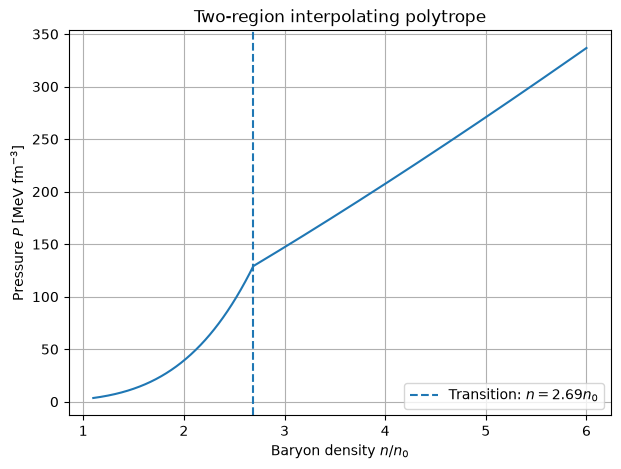

In [26]:

n_plot = np.linspace(n_begin, 6.0*n0, 1000)
P_plot = poly_pressure_n(n_plot)
plt.plot(n_plot/n0, P_plot)

plt.axvline(n_transition/n0, linestyle="--",label=fr"Transition: $n={n_transition/n0:.2f}n_0$")

plt.xlabel(r"Baryon density $n/n_0$")
plt.ylabel(r"Pressure $P$ [MeV fm$^{-3}$]")
plt.title("Two-region interpolating polytrope")
plt.legend()
plt.show()

In [27]:
# Low density Region EOS:
from scipy.optimize import brentq, root

T0 = 36.84
alpha = 5.87
eta = 3.81
gamma_chi = 4/3
hbarc = 197.3269804
mN = 939.0                  # MeV

# electron chemical potential
def mu_electron(n, x):
    return hbarc*(3*np.pi**2*x*n)**(1/3)

def deps_dx(n, x, alphaL, etaL):
    nb = n/n0
    A = 2*alpha - 4*alphaL
    B = 2*eta - 4*etaL

    return T0*((x**(2/3)-(1-x)**(2/3))*(2*nb)**(2/3)
               - A*(1-2*x)*nb
               + B*(1-2*x)*nb**gamma_chi)

def beta_x(n, alphaL, etaL):
    f = lambda x: deps_dx(n,x,alphaL,etaL) + mu_electron(n,x)
    return brentq(f, 1e-8, 0.499999)


In [28]:
# Nuclear equations for ep and P
def chiral_eps(n, x, alphaL, etaL):
    nb = n/n0

    kinetic = (3/5)*(x**(5/3)+(1-x)**(5/3))*(2*nb)**(2/3)

    A = ((2*alpha-4*alphaL)*x*(1-x) + alphaL)
    B = ((2*eta-4*etaL)*x*(1-x) + etaL)

    return T0*(kinetic - A*nb + B*nb**gamma_chi)
#Baryonic Pressure and electron pressure
def chiral_pressure(n, alphaL, etaL):
    x = beta_x(n, alphaL, etaL)
    nb = n/n0

    A = ((2*alpha-4*alphaL)*x*(1-x) + alphaL)
    B = ((2*eta-4*etaL)*x*(1-x) + etaL)

    Pb = n0*T0*((1/5)*(x**(5/3)+(1-x)**(5/3))*(2*nb)**(5/3)
                - A*nb**2 + gamma_chi*B*nb**(gamma_chi+1))

    mu_e = mu_electron(n,x)
    Pe = 0.25*mu_e*x*n

    return Pb + Pe

def chiral_energy(n, alphaL, etaL):
    x = beta_x(n, alphaL, etaL)
    eps = chiral_eps(n,x,alphaL,etaL)

    mu_e = mu_electron(n,x)
    Ee = 0.75*mu_e*x*n

    return n*(mN + eps) + Ee
    

In [30]:
#Restricting the region of our values for al between 1.18 - 1.59 and nl between 0.64 - 1.11
P_target = 3.542
mu_target = 977.5

def match_chiral(z):
    alphaL, etaL = z

    P = chiral_pressure(n_begin, alphaL, etaL)
    E = chiral_energy(n_begin, alphaL, etaL)
    mu = (E + P)/n_begin

    return [P-P_target, mu-mu_target]

alphaL, etaL = root(match_chiral, [1.5,1.05]).x

print("alphaL =", alphaL)
print("etaL =", etaL)
P_chi_end = chiral_pressure(n_begin, alphaL, etaL)
E_chi_end = chiral_energy(n_begin, alphaL, etaL)
mu_chi_end = (E_chi_end + P_chi_end)/n_begin

print("P =", P_chi_end)
print("E =", E_chi_end)
print("mu_B =", mu_chi_end)

alphaL = 1.4641889049557169
etaL = 1.0214198935378929
P = 3.54200000000025
E = 168.49800000000087
mu_B = 977.5000000000064


In [31]:
def combined_pressure_n(n):
    if np.isscalar(n):
        return chiral_pressure(n,alphaL,etaL) if n <= n_begin else poly_pressure_n(n)

    return np.array([
        chiral_pressure(ni,alphaL,etaL) if ni <= n_begin else poly_pressure_n(ni)
        for ni in n
    ])


def combined_energy_n(n):
    if np.isscalar(n):
        return chiral_energy(n,alphaL,etaL) if n <= n_begin else poly_energy_n(n)

    return np.array([
        chiral_energy(ni,alphaL,etaL) if ni <= n_begin else poly_energy_n(ni)
        for ni in n
    ])

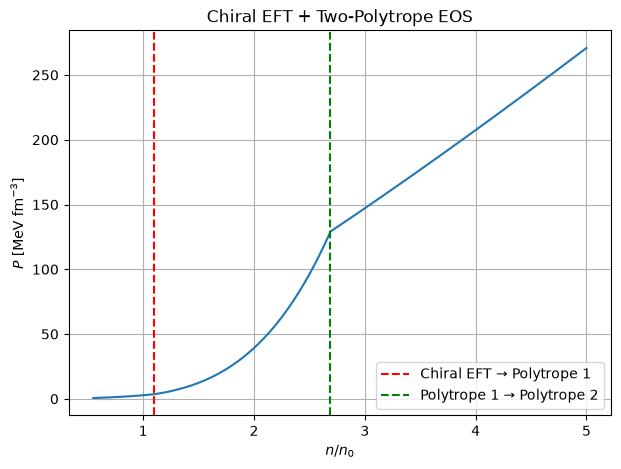

In [33]:
n_plot = np.linspace(0.55*n0, 5*n0, 700)

P_plot = combined_pressure_n(n_plot)
E_plot = combined_energy_n(n_plot)

plt.figure(figsize=(7,5))
plt.plot(n_plot/n0, P_plot)

plt.axvline(1.1, color="red", linestyle="--",
            label="Chiral EFT → Polytrope 1")

plt.axvline(n_transition/n0, color="green", linestyle="--",
            label="Polytrope 1 → Polytrope 2")

plt.xlabel(r"$n/n_0$")
plt.ylabel(r"$P$ [MeV fm$^{-3}$]")
plt.title("Chiral EFT + Two-Polytrope EOS")
plt.grid()
plt.legend()
plt.show()

In [35]:
# PQCD High density Region
# pQCD parameters for EOS II

X_pqcd = 1.2

c1 = 0.9008
d1 = 0.5034
d2 = 1.452
nu1 = 0.3553
nu2 = 0.9101

hbarc_GeVfm = 0.1973269804
mu_pqcd_begin = 2600.0 

def pqcd_ab(X):
    a = d1*X**(-nu1)
    b = d2*X**(-nu2)
    return a, b
#PSB term of noninteracting massless quark flavours
def pqcd_pressure_mu(muB, X=X_pqcd):
    u = muB/1000.0                     # MeV -> GeV
    a, b = pqcd_ab(X)

    P_SB = (3/(4*np.pi**2))*(u/3)**4
    P_nat = P_SB*(c1 - a/(u-b))

    return P_nat*1000/hbarc_GeVfm**3

# Baryon Number Density
def pqcd_number_density_mu(muB, X=X_pqcd):
    u = muB/1000.0
    a, b = pqcd_ab(X)

    C = 1/(108*np.pi**2)
    f = c1 - a/(u-b)
    fp = a/(u-b)**2

    return C*(4*u**3*f + u**4*fp)/hbarc_GeVfm**3

def pqcd_energy_mu(muB, X=X_pqcd):
    P = pqcd_pressure_mu(muB, X)
    n = pqcd_number_density_mu(muB, X)
    return muB*n - P



In [36]:
#SOS CHECK 
def pqcd_cs2_mu(muB, X=X_pqcd):
    u = muB/1000.0
    a, b = pqcd_ab(X)

    C = 1/(108*np.pi**2)
    f = c1 - a/(u-b)
    fp = a/(u-b)**2
    fpp = -2*a/(u-b)**3

    n = pqcd_number_density_mu(muB, X)

    dn_du = C*(12*u**2*f + 8*u**3*fp + u**4*fpp)/hbarc_GeVfm**3

    return n/(u*dn_du)
    

In [37]:
# End of second polytrope at mu_B = 2.6 GeV

n_poly_end = (n_transition**(gamma2-1)+ (gamma2-1)/(kappa2*gamma2)*(mu_end-mu_transition))**(1/(gamma2-1))

P_poly_end = poly_pressure_n(n_poly_end)
E_poly_end = poly_energy_n(n_poly_end)

# pQCD values
P_qcd_end = pqcd_pressure_mu(mu_end)
n_qcd_end = pqcd_number_density_mu(mu_end)
E_qcd_end = pqcd_energy_mu(mu_end)

print("Second polytrope:")
print("n =", n_poly_end, "fm^-3")
print("P =", P_poly_end, "MeV/fm^3")
print("E =", E_poly_end, "MeV/fm^3")

print("\npQCD:")
print("n =", n_qcd_end, "fm^-3")
print("P =", P_qcd_end, "MeV/fm^3")
print("E =", E_qcd_end, "MeV/fm^3")

Second polytrope:
n = 6.155707819073662 fm^-3
P = 3102.238196638293 MeV/fm^3
E = 12902.60213295323 MeV/fm^3

pQCD:
n = 6.178894510182841 fm^-3
P = 3104.5637057821496 MeV/fm^3
E = 12960.562020693238 MeV/fm^3


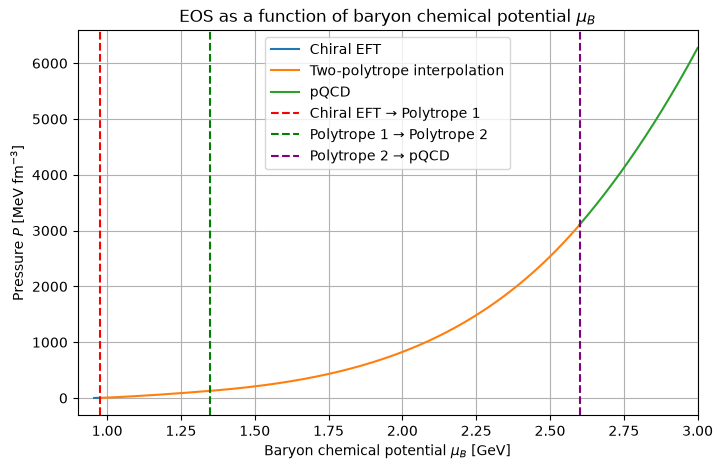

In [42]:
# Chiral EFT
n_chi = np.linspace(0.55*n0, n_begin, 250)
P_chi = np.array([chiral_pressure(n, alphaL, etaL) for n in n_chi])
E_chi = np.array([chiral_energy(n, alphaL, etaL) for n in n_chi])
mu_chi = (E_chi + P_chi)/n_chi

# Two polytropes
n_poly = np.linspace(n_begin, n_poly_end, 700)
P_poly = poly_pressure_n(n_poly)
mu_poly = poly_mu_n(n_poly)

# pQCD
mu_qcd = np.linspace(mu_end, 3000, 300)
P_qcd = pqcd_pressure_mu(mu_qcd)

plt.figure(figsize=(8,5))

plt.plot(mu_chi/1000, P_chi, label="Chiral EFT")
plt.plot(mu_poly/1000, P_poly, label="Two-polytrope interpolation")
plt.plot(mu_qcd/1000, P_qcd, label="pQCD")

plt.axvline(mu_begin/1000, color="red", linestyle="--",
            label="Chiral EFT → Polytrope 1")
plt.axvline(mu_transition/1000, color="green", linestyle="--",
            label="Polytrope 1 → Polytrope 2")
plt.axvline(mu_end/1000, color="purple", linestyle="--",
            label="Polytrope 2 → pQCD")

plt.xlabel(r"Baryon chemical potential $\mu_B$ [GeV]")
plt.ylabel(r"Pressure $P$ [MeV fm$^{-3}$]")
plt.title(r"EOS as a function of baryon chemical potential $\mu_B$")
plt.xlim(0.9, 3.0)
plt.grid()
plt.legend()
plt.show()